In [1]:
import numpy as np
import pandas as pd
import datetime as dt
import matplotlib.pyplot as plt
import xarray as xr

In [2]:
df_nao = pd.read_csv('daily_nao_ind_from_noaa.csv')
df_nao = df_nao.drop(columns='Unnamed: 0')
df_nao

,year,month,day,nao_index
0,1950,1,1,0.365
1,1950,1,2,0.096
2,1950,1,3,-0.416
3,1950,1,4,-0.616
4,1950,1,5,-0.261
...,...,...,...,...
27874,2026,4,26,-0.618
27875,2026,4,27,-0.079
27876,2026,4,28,0.360
27877,2026,4,29,0.594


In [3]:
df_nao.loc[20752, 'day'] = '26'
df_nao.loc[20752, 'nao_index'] = (df_nao.loc[20751, 'nao_index'] + df_nao.loc[20753, 'nao_index'])/2

df_nao.loc[20844, 'day'] = '26'
df_nao.loc[20844, 'nao_index'] = (df_nao.loc[20843, 'nao_index'] + df_nao.loc[20845, 'nao_index'])/2

In [4]:
df_nao['time'] = pd.to_datetime(df_nao[['year', 'month', 'day']])
df_nao = df_nao.set_index('time')
df_nao = df_nao.drop(['year', 'month', 'day'], axis=1)
df_nao

,nao_index
time,
1950-01-01,0.365
1950-01-02,0.096
1950-01-03,-0.416
1950-01-04,-0.616
1950-01-05,-0.261
...,...
2026-04-26,-0.618
2026-04-27,-0.079
2026-04-28,0.360


In [5]:
df_nao['nao_ind_rolling_mean'] = df_nao['nao_index'].rolling(window=dt.timedelta(days=7), min_periods=7, center=True).mean()
df_nao = df_nao.drop(['nao_index'], axis=1)
df_nao = df_nao.rename(columns={'nao_ind_rolling_mean':'nao_index'})

In [6]:
df_nao = df_nao[(df_nao.index < '2025-07') & (df_nao.index > '1950-06')]

In [7]:
month = df_nao.index.month
day = df_nao.index.day
df_nao_week0 = df_nao[((month == 12) & (day >= 4)) | (month == 1) | ((month == 2) & (day <= 25))]
df_nao_week1 = df_nao[((month == 11) & (day >= 27)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 18))]
df_nao_week2 = df_nao[((month == 11) & (day >= 20)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 11))]
df_nao_week3 = df_nao[((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4))]
df_nao_week3

,nao_index
time,
1950-11-13,0.092857
1950-11-14,0.081143
1950-11-15,-0.003286
1950-11-16,-0.168571
1950-11-17,-0.322714
...,...
2025-01-31,1.130857
2025-02-01,1.310714
2025-02-02,1.489714


<Axes: xlabel='time'>

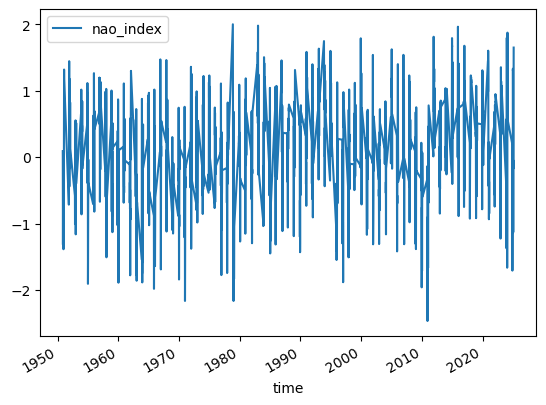

In [9]:
df_nao_week3.plot()

In [10]:
df_nao_week3.to_csv('NAO_week3.csv')

In [8]:
month = df_nao.index.month
day = df_nao.index.day
df_nao_week4 = df_nao[((month == 11) & (day >= 6)) | (month == 12) | ((month == 1) & (day <= 28))]
df_nao_week5 = df_nao[((month == 10) & (day >= 30)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 21))]
df_nao_week6 = df_nao[((month == 10) & (day >= 23)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 14))]
df_nao_week7 = df_nao[((month == 10) & (day >= 16)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 7))]
df_nao_week7

,nao_index
time,
1950-10-16,0.631143
1950-10-17,0.767714
1950-10-18,0.831714
1950-10-19,0.810714
1950-10-20,0.740000
...,...
2025-01-03,-0.495571
2025-01-04,-0.644714
2025-01-05,-0.810714


In [10]:
df_nao_week4.to_csv('NAO_week4.csv')
df_nao_week5.to_csv('NAO_week5.csv')

In [9]:
df_nao_week6.to_csv('NAO_week6.csv')
df_nao_week7.to_csv('NAO_week7.csv')

In [8]:
df_nao_week0.to_csv('NAO_week0.csv')
df_nao_week1.to_csv('NAO_week1.csv')
df_nao_week2.to_csv('NAO_week2.csv')